# fedOPD - the agentic decision layer

Roadmap step 4. Takes a demand forecast and turns it into a capacity decision: project each service
forward, classify the gap, escalate what a trust cannot solve alone, decide at the tier that can, and
release the allocation.

Reads `data/canonical/rtt_panel.parquet`, `provider_dim.csv` and `rtt_canonical.parquet`. Writes
`data/canonical/agent_decisions.csv`.

## The scope bounds, and they are hard

The data holds **no money, no staffing and no estate**. Capacity here means one thing only:
**treatments per month**, split admitted and non-admitted, which is what `Part_1A` and `Part_1B`
measure. "Fund a trust", "open beds", "hire consultants" are not expressible in this data and are not
claimed anywhere below.

Two more that are easy to blur and change what a result means:

- **Pathways are not patients.** Every count here is RTT clock starts and stops.
- **Independent-sector providers are private companies delivering NHS-funded care.** Capacity can be
  **bought** from them; it can never be **allocated** to them. That is why `provider_dim.csv` carries
  `fl_client` and `allocatable` as two separate flags rather than one.

## The removal term, split rather than lumped

`03_data_processing.ipynb` measured the leak in the backlog identity: about 15% of new referrals leave
the waiting list every month with no recorded completion, in the same direction in 95 months out of 95.
An agent that projects on `backlog = backlog + demand - completions` over-projects every month and
compounds it over the horizon, so it escalates harder than the data warrants.

NHS's own record-level linkage splits that leak, and the split is what matters rather than the total:

| share of unreported removals with a recorded reason, 2025 | what it actually is |
|---|---|
| 49% started treatment, recorded too late to count | **throughput that happened.** Real capacity |
| 23% decision not to treat | genuine exit from the list |
| 11% did not attend the first appointment | genuine exit, and a capacity slot burned |
| remainder | unattributed |

So roughly **half the leak is treatment that occurred**. Modelling it as a single attrition rate
understates capacity by that half, which is the specific failure this section exists to avoid.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CANON = Path("../data/canonical")
panel = pd.read_parquet(CANON / "rtt_panel.parquet")           # the 150 x 19 x 96 cube
dim = pd.read_csv(CANON / "provider_dim.csv")                  # per-provider attributes
canon = pd.read_parquet(CANON / "rtt_canonical.parquet")       # all providers, for independent context
index = pd.read_csv(CANON / "series_index.csv", parse_dates=["split_month"])   # the split 05 fixed

HORIZON = 6                                                    # months the board plans over
TARGET_PCT = 92.0                                              # the operational standard: 92% within 18 weeks

# NHS's published split of unreported removals, by recorded reason
TREATED, NOT_TREATED, DNA = 0.49, 0.23, 0.11                   # rest is unattributed

# WHERE THE AGENT STANDS. Not the last month in the file - that sits inside the sealed test year, and
# an agent standing there is making decisions nobody can check. It stands at the last TRAINING month
# instead, so the HORIZON months it plans over are months we can look up and score it against.
latest = index.split_month.iloc[0] - pd.DateOffset(months=1)   # last month before the evaluation window
actuals = panel[(panel.month > latest) &                       # what actually happened over the horizon,
                (panel.month <= latest + pd.DateOffset(months=HORIZON))]   # used only in section 9
print(f"standing at {latest:%Y-%m}, planning {HORIZON} months to "
      f"{latest + pd.DateOffset(months=HORIZON):%Y-%m}")
print(f"panel {panel.provider_code.nunique()} trusts x {panel.dept.nunique()} departments")

standing at 2024-03, planning 6 months to 2024-09
panel 150 trusts x 19 departments


## 1. The state vector

One row per service - a trust x department pair - describing where it stands now and how it has been
behaving. Only `usable` months contribute to the behavioural terms, so a suspended return cannot enter
the state as a month of zero activity.

| field | meaning |
|---|---|
| `waiting` | backlog stock, `Part_2` |
| `breach` | of those, waiting over 18 weeks |
| `crisis` | of those, waiting over 52 weeks |
| `within18_pct` | the measure the standard is written against |
| `capacity` | recent throughput, treatments per month |
| `adm_share` | how much of that throughput is admitted rather than non-admitted |
| `removal_rate` | measured per service, not inherited from the national figure |

In [2]:
RECENT = 12                                                    # the window the state is measured over
live = panel[panel.usable & (panel.month > latest - pd.DateOffset(months=RECENT))]

state = live.groupby(["provider_code", "dept"]).agg(
    capacity=("completed", "mean"),                            # treatments per month, recent average
    adm=("completed_admitted", "sum"),
    nonadm=("completed_nonadmitted", "sum"),
    demand_recent=("demand", "mean"),
    months=("month", "count"),
).reset_index()

# the stock terms come from the latest month alone: a backlog is a level, not an average
now = (panel[(panel.month == latest) & panel.usable]
       [["provider_code", "dept", "waiting", "waiting_gt18", "waiting_gt52", "waiting_dta"]]
       .rename(columns={"waiting_gt18": "breach", "waiting_gt52": "crisis"}))
state = state.merge(now, on=["provider_code", "dept"])

state["within18_pct"] = (1 - state.breach / state.waiting.where(state.waiting > 0)) * 100
state["adm_share"] = state.adm / (state.adm + state.nonadm).where(state.adm + state.nonadm > 0)
state = state[state.waiting > 0]                               # a service with no queue has no decision

print(f"services in scope: {len(state):,} of {panel.groupby(['provider_code','dept']).ngroups:,} cells")
print(f"  excluded: no queue at {latest:%Y-%m}, or the month was not usable")
print(f"\nwithin-18-weeks across the panel: {state.within18_pct.median():.1f}% median, "
      f"{(state.within18_pct >= TARGET_PCT).mean() * 100:.1f}% of services already at the standard")

services in scope: 2,046 of 2,850 cells
  excluded: no queue at 2024-03, or the month was not usable

within-18-weeks across the panel: 59.1% median, 7.3% of services already at the standard


## 2. The removal term, measured per service

The national 15% is not applied to every service. Each service's own removal rate is measured from its
own history using NHS's definition:

`unreported removals = list at start + clock starts - completed - list at end`

Services with too few usable months to measure fall back to the panel median, and that fallback is
counted rather than hidden.

In [3]:
seq = panel[panel.usable].sort_values("month")
seq["prev_waiting"] = seq.groupby(["provider_code", "dept"]).waiting.shift(1)   # last month's stock
seq["gap_months"] = seq.groupby(["provider_code", "dept"]).month.diff().dt.days   # detect a jump over a hole
seq = seq[seq.gap_months.between(20, 40)]                      # consecutive months only, ~30 days apart

# NHS's identity, rearranged for the term it does not publish
seq["removals"] = seq.prev_waiting + seq.demand - seq.completed - seq.waiting

rate = (seq.groupby(["provider_code", "dept"])
           .apply(lambda d: pd.Series({
               "removal_rate": d.removals.sum() / d.demand.sum() if d.demand.sum() > 0 else np.nan,
               "n": len(d)}), include_groups=False)
           .reset_index())
measurable = rate.n >= 24                                      # two years of consecutive months
fallback = rate.loc[measurable, "removal_rate"].median()
rate["removal_rate"] = rate.removal_rate.where(measurable, fallback)

state = state.merge(rate[["provider_code", "dept", "removal_rate"]], on=["provider_code", "dept"])
state["removal_rate"] = state.removal_rate.clip(-0.5, 0.9)     # a rate outside this is a data artefact

print(f"services with >= 24 consecutive usable months : {int(measurable.sum()):,}")
print(f"services falling back to the panel median      : {int((~measurable).sum()):,}")
print(f"panel median removal rate                      : {fallback * 100:.1f}% of demand")
print(f"national figure from 03_data_processing        : about 15% of demand")
print()
print("Split by NHS's recorded reasons, the median service loses:")
print(f"  {fallback * TREATED * 100:5.1f}% of demand as treatment that happened but was filed late")
print(f"  {fallback * NOT_TREATED * 100:5.1f}% as a decision not to treat")
print(f"  {fallback * DNA * 100:5.1f}% as a first-appointment DNA")
print("The first line is capacity. Counting it as attrition understates throughput by about half")
print("the leak, which is the error this split exists to prevent.")

services with >= 24 consecutive usable months : 2,198
services falling back to the panel median      : 0
panel median removal rate                      : 15.4% of demand
national figure from 03_data_processing        : about 15% of demand

Split by NHS's recorded reasons, the median service loses:
    7.6% of demand as treatment that happened but was filed late
    3.5% as a decision not to treat
    1.7% as a first-appointment DNA
The first line is capacity. Counting it as attrition understates throughput by about half
the leak, which is the error this split exists to prevent.


## 3. Project the backlog forward

Demand for the next `HORIZON` months comes from a forecast. The **seasonal-naive** forecast is used
here so this notebook runs without depending on `06_federated_forecast.ipynb` having been executed;
swapping in the federated forecast is one assignment, marked below.

The projection is the identity **with the removal term carried explicitly**:

`backlog[t+1] = backlog[t] + demand[t+1] - completed[t+1] - removals[t+1]`

and `removals` is split, so the treated portion is added back to effective capacity rather than
disappearing as loss.

In [4]:
# the demand forecast: same month one year earlier, per service
last_year = panel[panel.month > latest - pd.DateOffset(months=12)][
    ["provider_code", "dept", "month", "demand"]].copy()
last_year["fc_month"] = last_year.month + pd.DateOffset(months=12)     # project it forward a year
fc = last_year[last_year.fc_month <= latest + pd.DateOffset(months=HORIZON)]
fc = fc[fc.fc_month > latest]
# TO USE THE FEDERATED FORECAST INSTEAD: replace `fc` with 06's predictions on the same key.

demand_fc = fc.pivot_table(index=["provider_code", "dept"], columns="fc_month", values="demand")
demand_fc = demand_fc.reindex(pd.MultiIndex.from_frame(state[["provider_code", "dept"]])).fillna(0)
# HORIZON is 6 and the source window is 12 months, so this is always exactly HORIZON wide. Asserted
# rather than branched on: if it ever is not, the projection below is silently short of months.
assert demand_fc.shape[1] == HORIZON, f"forecast is {demand_fc.shape[1]} months, expected {HORIZON}"

# effective capacity: recorded throughput plus the removals that were treatment filed late
eff_capacity = state.capacity + state.removal_rate * TREATED * state.demand_recent
# genuine exits: decisions not to treat and DNAs leave the list without consuming a treatment slot
exit_rate = state.removal_rate * (NOT_TREATED + DNA)

backlog = state.waiting.to_numpy(dtype=float)                  # the stock we roll forward
breach = state.breach.to_numpy(dtype=float)
path = [backlog.copy()]
for h in range(HORIZON):
    d = demand_fc.iloc[:, h].to_numpy()                        # this month's forecast demand
    backlog = np.clip(backlog + d - eff_capacity.to_numpy() - exit_rate.to_numpy() * d, 0, None)
    path.append(backlog.copy())
path = np.array(path)                                          # (HORIZON+1, n_services)

state["projected_waiting"] = path[-1]
state["projected_change"] = state.projected_waiting - state.waiting

# the breach count moves with the queue: a queue that grows ages, and the standard is about age
state["projected_breach"] = np.clip(
    breach + (state.projected_waiting - state.waiting) * (breach / state.waiting.where(state.waiting > 0)),
    0, state.projected_waiting)
state["projected_within18"] = (1 - state.projected_breach / state.projected_waiting.where(
    state.projected_waiting > 0)) * 100

print(f"panel waiting list {state.waiting.sum():>12,.0f} now")
print(f"                   {state.projected_waiting.sum():>12,.0f} projected at "
      f"{latest + pd.DateOffset(months=HORIZON):%Y-%m}")
print(f"                   {state.projected_change.sum():>+12,.0f} change")
print()
print("Without the removal term the same projection gives:")
naive = state.waiting + (demand_fc.to_numpy().sum(axis=1) - state.capacity * HORIZON)
print(f"                   {np.clip(naive, 0, None).sum():>12,.0f}  "
      f"({np.clip(naive, 0, None).sum() / state.projected_waiting.sum() - 1:+.1%} vs the corrected figure)")
print("That difference is the size of the escalation the naive identity would raise for nothing.")

panel waiting list    7,062,073 now
                      7,051,569 projected at 2024-09
                        -10,504 change

Without the removal term the same projection gives:
                      8,241,436  (+16.9% vs the corrected figure)
That difference is the size of the escalation the naive identity would raise for nothing.


## 4. Gap classification

Each service lands in one of four states. The thresholds are stated here rather than tuned, because
this is a decision rule and a tuned threshold on the same data it is evaluated on is not a rule.

| class | condition |
|---|---|
| `on_track` | projected to meet 92% within 18 weeks |
| `slack` | at the standard now **and** the queue is projected to shrink - can give capacity away |
| `behind` | below the standard, but no 52-week waits |
| `crisis` | 52-week waits on the books |

In [5]:
at_standard = state.projected_within18 >= TARGET_PCT
shrinking = state.projected_change < 0

state["klass"] = np.select(
    [state.crisis > 0,                                         # any 52-week wait is a crisis, full stop
     ~at_standard,                                             # below the standard at the horizon
     at_standard & shrinking],                                 # comfortable and getting better
    ["crisis", "behind", "slack"],
    default="on_track")

print(state.klass.value_counts().to_string())
print()
print("by specialty, share of services in crisis:")
by_dept = (state.assign(c=state.klass.eq("crisis"))
                .groupby("dept").agg(services=("c", "size"), crisis_pct=("c", lambda s: s.mean() * 100))
                .sort_values("crisis_pct", ascending=False))
print(by_dept.round(1).head(10).to_string())
print()
print("C_130 Ophthalmology caveat: it is both the largest department by volume and the fastest-")
print("substituting one, with independent share rising from 6.2% to 19.6% across the window. Trust-")
print("level ophthalmology trends are therefore partly sector shift, not population change.")

klass
crisis      1642
behind       291
on_track      62
slack         51

by specialty, share of services in crisis:
         services  crisis_pct
dept                         
C_502         120        95.8
C_100         118        95.8
C_120         116        94.8
C_110         127        94.5
C_140         110        93.6
C_101         117        92.3
C_130         111        90.1
C_301         120        90.0
X_OTHER       145        89.7
C_160          84        83.3

C_130 Ophthalmology caveat: it is both the largest department by volume and the fastest-
substituting one, with independent share rising from 6.2% to 19.6% across the window. Trust-
level ophthalmology trends are therefore partly sector shift, not population change.


## 5. The capacity ask

For every service not on track, how many extra treatments per month over the horizon would bring the
projected breach count down to the standard. Split admitted and non-admitted by that service's own
recent mix, because the two are not interchangeable resources.

This is the quantity the escalation carries. It is deliberately **not** money, staff or beds.

In [6]:
need = state.klass.isin(["behind", "crisis"])

# the breach count that would satisfy the standard at the projected queue size
allowed = state.projected_waiting * (1 - TARGET_PCT / 100)
excess = np.clip(state.projected_breach - allowed, 0, None)    # pathways that must be cleared
state["ask_per_month"] = np.where(need, excess / HORIZON, 0)   # spread evenly over the horizon
# a service with a queue but no completions in the window has no measured split of its own; it takes
# the panel median rather than an invented 50/50
state["ask_admitted"] = state.ask_per_month * state.adm_share.fillna(state.adm_share.median())
state["ask_nonadmitted"] = state.ask_per_month - state.ask_admitted

# what a service in slack can offer: throughput above what its own projected queue needs
state["offer_per_month"] = np.where(state.klass.eq("slack"),
                                    np.clip(-state.projected_change / HORIZON, 0, state.capacity * 0.1), 0)

print(f"services asking for capacity : {int(need.sum()):,}")
print(f"total ask                    : {state.ask_per_month.sum():,.0f} treatments per month")
print(f"  admitted                   : {state.ask_admitted.sum():,.0f}")
print(f"  non-admitted               : {state.ask_nonadmitted.sum():,.0f}")
print(f"services able to offer slack : {int(state.klass.eq('slack').sum()):,}")
print(f"total offer                  : {state.offer_per_month.sum():,.0f} treatments per month")
print()
print("The offer is capped at 10% of a service's own recent throughput. A service cannot lend more")
print("than it plausibly has spare, and an uncapped offer makes the allocation arithmetic work by")
print("assuming capacity that does not exist.")

services asking for capacity : 1,933
total ask                    : 419,220 treatments per month
  admitted                   : 81,379
  non-admitted               : 337,841
services able to offer slack : 51
total offer                  : 657 treatments per month

The offer is capped at 10% of a service's own recent throughput. A service cannot lend more
than it plausibly has spare, and an uncapped offer makes the allocation arithmetic work by
assuming capacity that does not exist.


## 6. Escalation - trust, then ICB, then national

Three tiers, each solving what it can and passing up only the residual.

1. **Trust.** A trust moves capacity between its **own** departments first. No coordination cost, no
   external decision, so it happens before anything is escalated.
2. **ICB.** Unmet asks go to the trust's ICB, which reallocates between the **allocatable** trusts it
   commissions. The `own_icb_share` measured in `03` is the caveat on this tier: a trust drawing most
   of its referrals from other ICBs is only partly governed by its own.
3. **National.** Whatever no ICB could close.

Allocation within a tier is proportional to the size of each ask, so no service is starved by ordering.

In [7]:
state = state.merge(dim[["provider_code", "icb", "allocatable"]], on="provider_code", how="left")
assert state.allocatable.all(), "a non-allocatable provider reached the allocation - panel is public only"

state["unmet"] = state.ask_per_month                           # what each service still needs
state["spare"] = state.offer_per_month                         # what each service can still give

def settle(group_keys, label):
    # Inside each group, place as much as the group holds: min(total ask, total offer). Askers take
    # their share of that in proportion to their ask, offerers give up their share in proportion to
    # their offer. Both sides are updated, so tier 2 only ever sees what tier 1 left behind.
    g = state.groupby(group_keys)
    ask_tot = g.unmet.transform("sum")
    off_tot = g.spare.transform("sum")
    moved = np.minimum(ask_tot, off_tot)                       # the group can place no more than this
    got = np.where(ask_tot > 0, state.unmet / ask_tot * moved, 0)
    given = np.where(off_tot > 0, state.spare / off_tot * moved, 0)
    print(f"{label:22s} ask {state.unmet.sum():>10,.0f} | offer {state.spare.sum():>10,.0f} | "
          f"placed {got.sum():>10,.0f} | left {state.unmet.sum() - got.sum():>10,.0f}")
    state["unmet"] = state.unmet - got
    state["spare"] = state.spare - given
    assert abs(got.sum() - given.sum()) < 1, "capacity was created or destroyed in the allocation"

settle(["provider_code"], "tier 1 - within trust")             # a trust moves capacity between its own depts
settle(["icb"], "tier 2 - within ICB")                         # then between the trusts one ICB commissions

national = state.unmet.sum()
print(f"{'tier 3 - national':22s} residual {national:>10,.0f} treatments per month, "
      f"{int((state.unmet > 0).sum()):,} services still short")

tier 1 - within trust  ask    419,220 | offer        657 | placed        349 | left    418,870
tier 2 - within ICB    ask    418,870 | offer        308 | placed        308 | left    418,562
tier 3 - national      residual    418,562 treatments per month, 1,870 services still short


## 7. The independent sector as purchasable capacity

What the national tier cannot allocate, it can consider buying. Independent providers are **not**
clients and **not** allocatable; they are a market. The relevant question is where that market actually
has volume, per specialty and per ICB, which is context the board needs before a purchase is plausible.

`04_eda.ipynb` measured the constraint that governs this tier: independent share does **not** respond
to public backlog at a monthly cadence. Correlations of differenced share against differenced backlog
are near zero at lags 0, 3, 6 and 12. Substitution here is a multi-year contracting shift, not a valve
that can be opened inside a 6-month planning horizon.

In [8]:
ind = canon[(canon.sector == "independent") & (canon.month > latest - pd.DateOffset(months=12))]
ind_cap = ind.groupby("dept").completed.sum() / 12             # independent treatments per month
ask_by_dept = state.groupby("dept").unmet.sum()                # what national could not place

market = pd.DataFrame({"unmet_ask": ask_by_dept, "independent_capacity": ind_cap}).fillna(0)
market["ask_as_pct_of_market"] = market.unmet_ask / market.independent_capacity.replace(0, np.nan) * 100
print(market[market.unmet_ask > 0].sort_values("unmet_ask", ascending=False).round(1).to_string())
print()
print("Read this as market size, not as available capacity. Independent throughput is already")
print("committed to the pathways it is delivering; the column says how large the sector is relative")
print("to the shortfall, which is the first thing that makes a purchase plausible or not.")
print()
print("Independents DO attach to a region, via Commissioner Parent Org Code rather than ownership")
print("(F-41/F-40): 96.9% of independent rows carry one, 30 of 42 values are known ICB codes")
print("covering 72.4% of rows. So this CAN be resolved at the ICB tier - not yet wired in here.")

         unmet_ask  independent_capacity  ask_as_pct_of_market
dept                                                          
X_OTHER    82041.8               47983.1                 171.0
C_110      47742.4              102790.4                  46.4
C_120      43344.5               16080.0                 269.6
C_502      36825.9               14508.7                 253.8
C_130      28706.1              111892.4                  25.7
C_100      25756.7               27709.2                  93.0
C_330      23056.7               46309.5                  49.8
C_101      22173.2               12249.0                 181.0
C_140      22028.7                5700.4                 386.4
C_320      21799.0                2393.3                 910.8
C_301      20345.5               19057.1                 106.8
C_400      14829.8                 719.2                2061.8
C_340      10620.7                 561.9                1890.1
C_160       7042.2                2472.3               

## 8. Release the decision

In [9]:
out = state[["provider_code", "dept", "icb", "klass", "waiting", "breach", "crisis",
             "within18_pct", "capacity", "removal_rate", "projected_waiting", "projected_within18",
             "ask_per_month", "ask_admitted", "ask_nonadmitted", "offer_per_month", "unmet"]].copy()
out["decision_month"] = latest
out["horizon_months"] = HORIZON
out = out.sort_values("unmet", ascending=False)
out.to_csv(CANON / "agent_decisions.csv", index=False)

print(f"written: agent_decisions.csv, {len(out):,} services")
print()
print("Ten largest unmet asks:")
print(out.head(10)[["provider_code", "dept", "klass", "within18_pct",
                    "projected_within18", "ask_per_month", "unmet"]].round(1).to_string(index=False))

written: agent_decisions.csv, 2,046 services

Ten largest unmet asks:
provider_code    dept  klass  within18_pct  projected_within18  ask_per_month  unmet
          RJ1 X_OTHER crisis          55.2                55.2         4497.8 4497.8
          R0A X_OTHER crisis          50.8                50.8         3808.8 3806.8
          RYR X_OTHER crisis          45.0                45.0         2649.5 2649.5
          RAJ   C_110 crisis          45.8                45.8         2352.5 2352.5
          RJZ X_OTHER crisis          60.2                60.2         2193.6 2193.6
          RAJ X_OTHER crisis          59.8                59.8         2168.1 2168.1
          R1H X_OTHER crisis          56.5                56.5         2082.6 2082.6
          RRK X_OTHER crisis          52.5                52.5         2013.7 2013.7
          REM X_OTHER crisis          53.2                53.2         1919.3 1914.3
          RAL X_OTHER crisis          57.9                57.9         1820.0 18

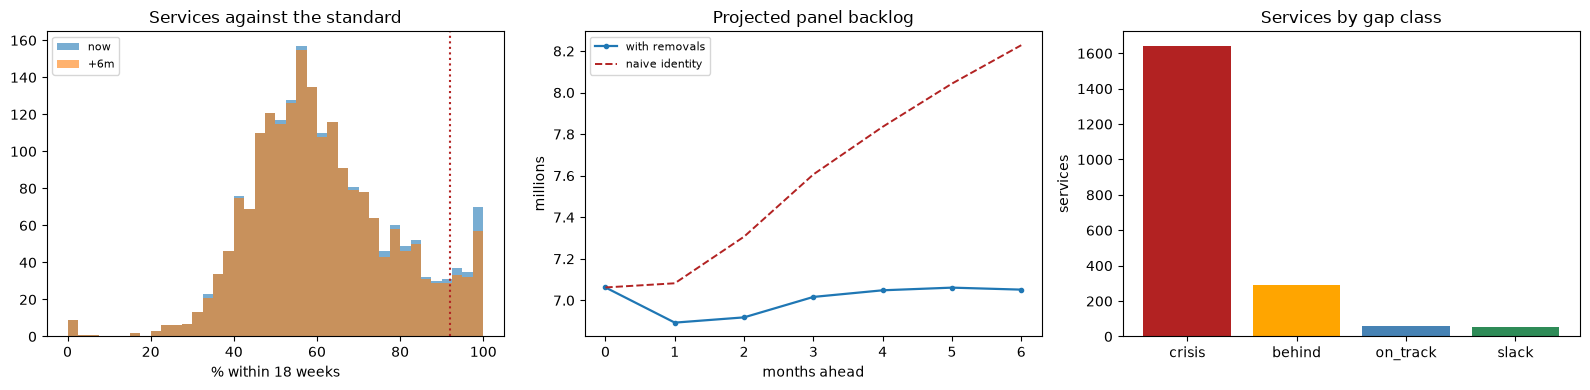

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# where the panel sits against the standard, now and projected
ax[0].hist(state.within18_pct.dropna(), bins=40, alpha=0.6, label="now")
ax[0].hist(state.projected_within18.dropna(), bins=40, alpha=0.6, label=f"+{HORIZON}m")
ax[0].axvline(TARGET_PCT, color="firebrick", ls=":")           # the standard
ax[0].set_xlabel("% within 18 weeks"); ax[0].set_title("Services against the standard"); ax[0].legend(fontsize=8)

# the projected panel backlog, with and without the removal term
ax[1].plot(range(HORIZON + 1), path.sum(axis=1) / 1e6, lw=1.6, marker="o", ms=3, label="with removals")
naive_path = state.waiting.sum() + np.cumsum(
    [0] + [demand_fc.iloc[:, h].sum() - state.capacity.sum() for h in range(HORIZON)])
ax[1].plot(range(HORIZON + 1), naive_path / 1e6, lw=1.4, ls="--", color="firebrick", label="naive identity")
ax[1].set_xlabel("months ahead"); ax[1].set_ylabel("millions"); ax[1].legend(fontsize=8)
ax[1].set_title("Projected panel backlog")

# who is asking, by class
counts = state.klass.value_counts()
ax[2].bar(counts.index, counts.to_numpy(), color=["firebrick", "orange", "steelblue", "seagreen"][:len(counts)])
ax[2].set_title("Services by gap class"); ax[2].set_ylabel("services")
plt.tight_layout()

## What this is and is not

**Measured:** the state of every service at the latest month, the removal rate per service from that
service's own history, and the size of the ask implied by the standard.

**Assumed:** that recent throughput is what a service will sustain, that the breach count moves in
proportion to the queue, and that the removal split observed nationally applies to every service. All
three are stated in the code and none is estimated from the data.

**Not claimed:** anything about money, staffing, estate or beds; anything per patient; and any
suggestion that a trust can be "expanded" or "upgraded". None of those exist in this collection.

**The rules are stated, not tuned.** The 92% target is NHS's own; the 10% offer cap and the 24-month
measurement minimum are declared choices. Tuning them against the same data they are evaluated on
would make the decision layer fit its own test.

## 9. Back-test — was the projection right?

The agent stands at the last training month and projects `HORIZON` months forward. Those months have
already happened, so the projection can be scored rather than admired.

This is the only part of the notebook that is an evaluation rather than a decision, and it answers one
question: **does the removal-corrected identity project the backlog better than the naive one it
replaced?** If it does not, the correction is decoration and the escalation sizes built on it are
wrong by whatever the gap is.

Note what this does *not* test. It scores the **projection**, not the allocation. Whether the
escalation would have improved anything is a counterfactual — the capacity moves it proposes never
happened — and no amount of held-out data makes that checkable. Stated so the two are not conflated.

In [11]:
# what the backlog actually did over the horizon, per service
end_month = latest + pd.DateOffset(months=HORIZON)
truth = (actuals[actuals.month == end_month][["provider_code", "dept", "waiting"]]
         .rename(columns={"waiting": "actual_waiting"}))

bt = state.merge(truth, on=["provider_code", "dept"], how="inner")   # services present at both ends
bt["naive_waiting"] = np.clip(                                      # the identity WITHOUT removals
    bt.waiting + demand_fc.to_numpy().sum(axis=1)[bt.index] - bt.capacity * HORIZON, 0, None)

for label, col in [("with removal term", "projected_waiting"), ("naive identity", "naive_waiting")]:
    err = bt[col] - bt.actual_waiting
    print(f"{label:20s} MAE {err.abs().mean():9,.0f} | bias {err.mean():+10,.0f} | "
          f"total projected {bt[col].sum() / 1e6:6.2f}m vs actual {bt.actual_waiting.sum() / 1e6:.2f}m")

corrected = (bt.projected_waiting - bt.actual_waiting).abs().mean()
naive = (bt.naive_waiting - bt.actual_waiting).abs().mean()
print(f"\nservices scored: {len(bt):,}   horizon: {latest:%Y-%m} -> {end_month:%Y-%m}")
print(f"the removal correction changes per-service MAE by {(corrected / naive - 1) * 100:+.1f}%")
print("Positive means the correction made the projection WORSE, which is a result and gets reported.")


with removal term    MAE       682 | bias        -16 | total projected   7.05m vs actual 7.08m
naive identity       MAE       990 | bias       +565 | total projected   8.24m vs actual 7.08m

services scored: 2,046   horizon: 2024-03 -> 2024-09
the removal correction changes per-service MAE by -31.0%
Positive means the correction made the projection WORSE, which is a result and gets reported.
